## 0. Setup Awal

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = 'outputLogisticRegressionComparison'
os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.rcParams['figure.dpi'] = 120

## 1. Data Understanding

### 1.1 Load Hasil Evaluasi

In [6]:
files = {
    'L1': 'outputLogisticRegressionL1AntiBurnout/metrics_logistic_regression_l1.csv',
    'L2': 'outputLogisticRegressionL2AntiBurnout/metrics_logistic_regression_l2.csv',
    'Elastic Net': 'outputLogisticRegressionElastic_NetAntiBurnout/metrics_logistic_regression_elastic_net.csv'
}

results = []
for name, path in files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f'File hasil {name} belum ditemukan: {path}')
    data = pd.read_csv(path)
    data['Regularization'] = name
    results.append(data)

df_comparison = pd.concat(results, ignore_index=True)
display(df_comparison)

,Model,Penalty,L1_Ratio,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB,Regularization
0,Logistic Regression L1,l1,NaN,0.01,0.989,0.9827,0.9879,0.985,0.989,0.9852,0.9799,0.7031,4.6107,L1
1,Logistic Regression L2,l2,NaN,0.10,0.989,0.9827,0.9879,0.985,0.989,0.9850,0.9796,0.7031,29.0999,L2
2,Logistic Regression Elastic Net,elasticnet,0.75,0.01,0.989,0.9827,0.9879,0.985,0.989,0.9852,0.9799,1.3594,4.7340,Elastic Net


## 2. Preprocessing

### 2.1 Penyusunan Tabel Perbandingan

In [7]:
metric_columns = [
    'Accuracy', 'Precision_Macro', 'Recall_Macro',
    'F1_Score_Macro', 'F1_Score_Weighted'
]

display(df_comparison[['Regularization'] + metric_columns])

,Regularization,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted
0,L1,0.989,0.9827,0.9879,0.985,0.989
1,L2,0.989,0.9827,0.9879,0.985,0.989
2,Elastic Net,0.989,0.9827,0.9879,0.985,0.989


## 3. Modeling

### 3.1 Perbandingan Metrik Evaluasi

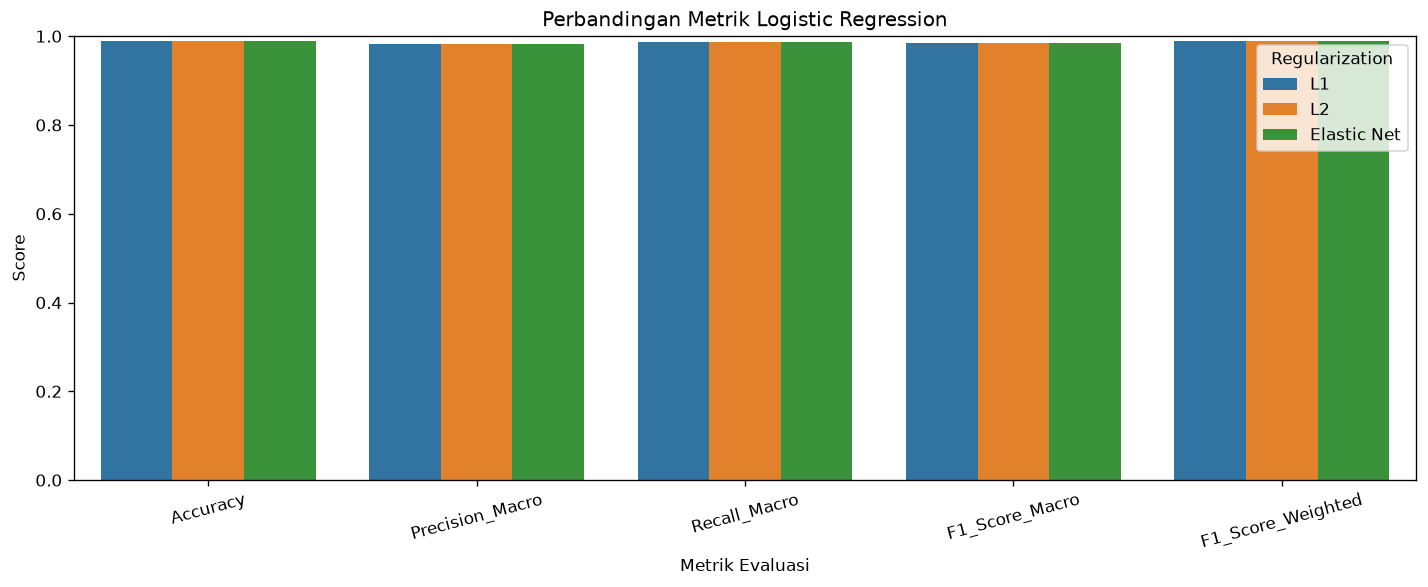

In [8]:
plot_data = df_comparison.melt(
    id_vars='Regularization',
    value_vars=metric_columns,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_data, x='Metric', y='Score', hue='Regularization')
plt.title('Perbandingan Metrik Logistic Regression')
plt.ylabel('Score')
plt.xlabel('Metrik Evaluasi')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Evaluasi

### 4.1 Perbandingan Stratified 5-Fold Cross-Validation

In [9]:
cv_files = {
    'L1': 'outputLogisticRegressionL1AntiBurnout/cv_5fold_logistic_regression_l1.csv',
    'L2': 'outputLogisticRegressionL2AntiBurnout/cv_5fold_logistic_regression_l2.csv',
    'Elastic Net': 'outputLogisticRegressionElastic_NetAntiBurnout/cv_5fold_logistic_regression_elastic_net.csv'
}

cv_frames = []
for name, path in cv_files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f'File CV {name} belum ditemukan: {path}')
    data = pd.read_csv(path)
    data['Regularization'] = name
    cv_frames.append(data)

df_cv_comparison = pd.concat(cv_frames, ignore_index=True)
display(df_cv_comparison)

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),Regularization
0,Fold 1,0.988750,0.982353,0.987603,0.984621,0.988796,L1
1,Fold 2,0.990000,0.984221,0.988981,0.986317,0.990037,L1
2,Fold 3,0.981250,0.971591,0.979339,0.974502,0.981367,L1
3,Fold 4,0.987500,0.980507,0.986226,0.982927,0.987556,L1
4,Fold 5,0.978750,0.968343,0.976487,0.971196,0.978891,L1
5,Mean,0.985250,0.977403,0.983727,0.979913,0.985330,L1
6,Std,0.004430,0.006269,0.004910,0.005959,0.004388,L1
7,Fold 1,0.988750,0.982353,0.987603,0.984621,0.988796,L2
8,Fold 2,0.990000,0.984221,0.988981,0.986317,0.990037,L2
9,Fold 3,0.980000,0.969967,0.977268,0.972779,0.980119,L2


### 4.2 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [10]:
display(df_comparison[[
    'Regularization', 'C', 'L1_Ratio', 'Training_Time_s', 'Peak_Memory_MB'
]])

,Regularization,C,L1_Ratio,Training_Time_s,Peak_Memory_MB
0,L1,0.01,NaN,0.7031,4.6107
1,L2,0.10,NaN,0.7031,29.0999
2,Elastic Net,0.01,0.75,1.3594,4.7340


## 5. Visualisasi Hasil

### 5.1 Visualisasi Metrik Evaluasi

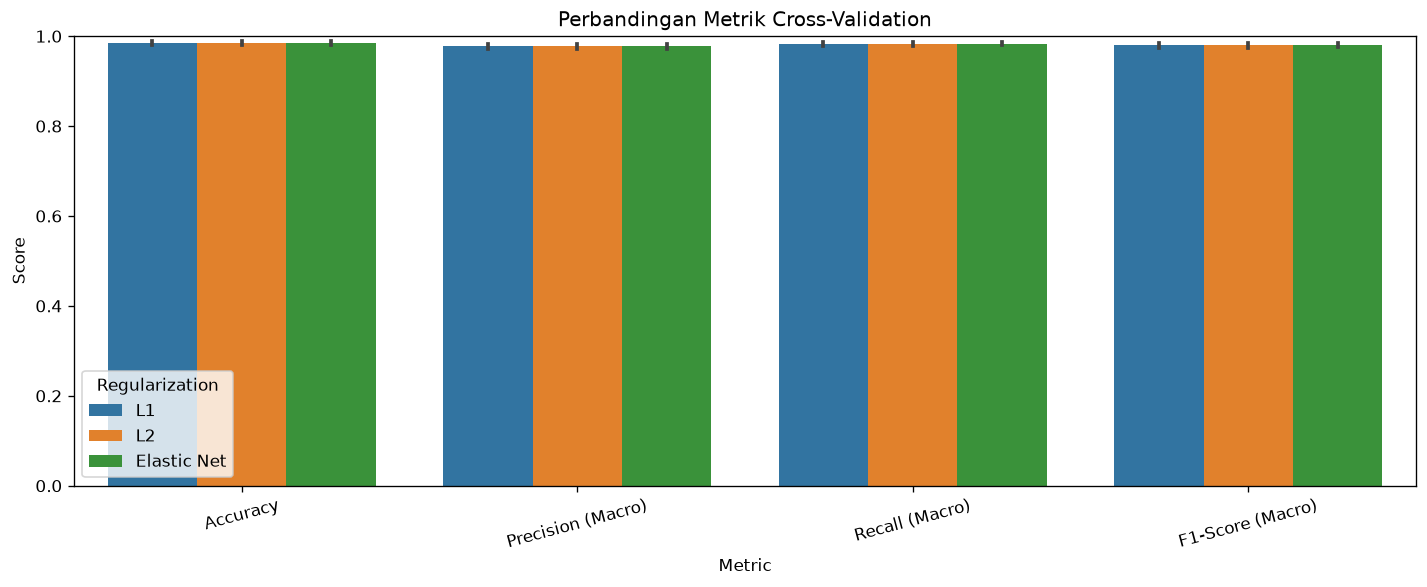

In [11]:
cv_metric_columns = [
    'Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'
]

cv_summary = df_cv_comparison[df_cv_comparison['Fold'].isin([f'Fold {i}' for i in range(1, 6)])]
cv_long = cv_summary.melt(
    id_vars=['Fold', 'Regularization'],
    value_vars=cv_metric_columns,
    var_name='Metric', value_name='Score'
)

plt.figure(figsize=(12, 5))
sns.barplot(data=cv_long, x='Metric', y='Score', hue='Regularization')
plt.title('Perbandingan Metrik Cross-Validation')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Analisis

### 6.1 Penentuan Model Terbaik

In [12]:
best_model = df_comparison.sort_values(
    by='F1_Score_Macro', ascending=False
).iloc[0]

print('Model dengan F1-Score Macro tertinggi:')
print(best_model[['Regularization', 'F1_Score_Macro', 'Accuracy', 'C', 'L1_Ratio']])

Model dengan F1-Score Macro tertinggi:
Regularization       L1
F1_Score_Macro    0.985
Accuracy          0.989
C                  0.01
L1_Ratio            NaN
Name: 0, dtype: object


## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [13]:
df_comparison.to_csv(
    f'{OUTPUT_DIR}/comparison_metrics.csv', index=False
)
df_cv_comparison.to_csv(
    f'{OUTPUT_DIR}/comparison_cv_5fold.csv', index=False
)
print('File perbandingan berhasil disimpan.')

File perbandingan berhasil disimpan.
